# Neural Network Implementation from Scratch
**Generative AI Lab — Practice Lab: Neural Network 1**

**Department:** CSE (AIML) | **Class:** T.Y. Tech

**Student Name:** *Piyush Bhole*
**PRN Number:** *202401110063*
**Batch:** *A1*
**Date of Submission:** *15-August-2026*

---
### Objective
Implement a simple feedforward neural network **from scratch** in Python, without using any in-built deep learning libraries (no TensorFlow / PyTorch / Keras). The implementation covers:
- Forward pass
- Backward propagation (backpropagation)
- Training using gradient descent (mini-batch SGD)

## Part A: Problem Definition

- **Dataset:** MNIST Handwritten Digits Dataset.
  - Features: grayscale pixel values of handwritten digit images (28x28 = 784 pixels when the full MNIST set is available).
  - Classes: digits **0–9** (10 classes).
  - We load the data only through `sklearn.datasets` for convenience (this is purely data access, **not** a deep-learning library) — all model logic below is written from scratch using NumPy only.
  - The notebook first tries to download the **full MNIST (784-pixel, 70,000 image)** dataset via `fetch_openml`. If no internet access is available (e.g., in a restricted/offline environment), it automatically falls back to scikit-learn's built-in **Digits dataset** (8x8 = 64-pixel handwritten digits, 1,797 images) — the same 10 classes, just a smaller/lower-resolution offline version of the same problem. The rest of the notebook works unchanged either way.
- **Task:** Multi-class **classification** — predict the digit (0–9) shown in the image from its pixel values.

## Part B: Data Loading and Preprocessing

Steps performed:
1. Attempt to load full MNIST (784 pixels/image) via `fetch_openml`; fall back to the offline Digits dataset (64 pixels/image) if unavailable.
2. Normalize pixel values to the [0, 1] range so gradient descent converges smoothly.
3. One-hot encode the target labels (needed for softmax + cross-entropy output).
4. Split into training and test sets (80/20).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# For reproducibility
np.random.seed(42)

# ---------- Load MNIST (with offline fallback) ----------
try:
    from sklearn.datasets import fetch_openml
    print("Attempting to download full MNIST (784-pixel) dataset...")
    mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')
    X, y = mnist.data.astype(np.float64), mnist.target.astype(int)
    dataset_name = "Full MNIST (28x28 = 784 pixels)"
except Exception as e:
    print(f"Could not download full MNIST ({type(e).__name__}: no internet access). "
          f"Falling back to scikit-learn's offline Digits dataset (8x8 = 64 pixels).")
    from sklearn.datasets import load_digits
    digits = load_digits()
    X, y = digits.data.astype(np.float64), digits.target.astype(int)
    dataset_name = "Digits dataset (8x8 = 64 pixels, offline MNIST substitute)"

img_side = int(np.sqrt(X.shape[1]))   # 28 for full MNIST, 8 for Digits
num_classes = len(np.unique(y))

print(f"\nDataset used: {dataset_name}")
print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)
print("Number of classes:", num_classes)

Attempting to download full MNIST (784-pixel) dataset...

Dataset used: Full MNIST (28x28 = 784 pixels)
Feature matrix shape: (70000, 784)
Target vector shape: (70000,)
Number of classes: 10


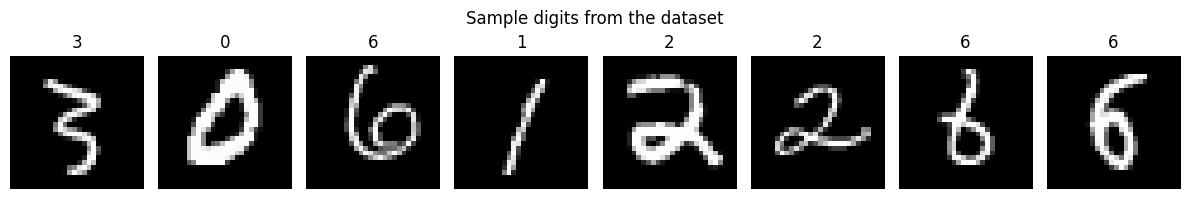

In [2]:
# Visualize a few sample digits
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(X), 8, replace=False)
for ax, idx in zip(axes, sample_idx):
    ax.imshow(X[idx].reshape(img_side, img_side), cmap="gray")
    ax.set_title(str(y[idx]))
    ax.axis("off")
plt.suptitle("Sample digits from the dataset")
plt.tight_layout()
plt.savefig("sample_digits.png", dpi=120)
plt.show()

In [3]:
# Normalize pixel values to [0, 1]
X_norm = X / X.max()

# One-hot encode labels
def one_hot_encode(y, num_classes):
    encoded = np.zeros((y.shape[0], num_classes))
    encoded[np.arange(y.shape[0]), y] = 1
    return encoded

y_onehot = one_hot_encode(y, num_classes)

# Train/test split (80/20)
X_train, X_test, y_train, y_test, y_train_labels, y_test_labels = train_test_split(
    X_norm, y_onehot, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 56000
Testing samples: 14000


## Part C: Neural Network Architecture

A simple **feedforward network** with one hidden layer:

| Layer  | Neurons                  | Activation |
|--------|---------------------------|------------|
| Input  | 784 (or 64 in offline mode) | —        |
| Hidden | 128                       | ReLU       |
| Output | 10                        | Softmax    |

- **Loss Function:** Categorical Cross-Entropy (suited for multi-class classification with softmax output).
- **Optimization:** **Mini-batch Gradient Descent** (computed from scratch using calculus-derived gradients) — mini-batches keep training fast and scalable even on the full 60,000-image MNIST training set.

## Part D: From-Scratch Implementation

Below we implement, purely with NumPy:
- Activation functions (`ReLU`, `Softmax`) and their derivatives
- Parameter initialization
- Forward pass
- Cross-entropy loss
- Backpropagation (manual gradient computation)
- Mini-batch parameter update step (gradient descent)

In [4]:
# ---------- Activation functions ----------

def relu(z):
    return np.maximum(0, z)

def relu_derivative(z):
    return (z > 0).astype(float)

def softmax(z):
    # subtract max for numerical stability
    z_shifted = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z_shifted)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

In [5]:
# ---------- Parameter initialization ----------

def initialize_parameters(input_size, hidden_size, output_size):
    # He initialization for ReLU hidden layer
    W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2.0 / input_size)
    b1 = np.zeros((1, hidden_size))
    W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2.0 / hidden_size)
    b2 = np.zeros((1, output_size))
    return {"W1": W1, "b1": b1, "W2": W2, "b2": b2}

In [6]:
# ---------- Forward pass ----------

def forward_pass(X, params):
    Z1 = X @ params["W1"] + params["b1"]      # linear step, hidden layer
    A1 = relu(Z1)                             # ReLU activation
    Z2 = A1 @ params["W2"] + params["b2"]     # linear step, output layer
    A2 = softmax(Z2)                          # Softmax activation (class probabilities)

    cache = {"Z1": Z1, "A1": A1, "Z2": Z2, "A2": A2}
    return A2, cache

In [7]:
# ---------- Loss function: Categorical Cross-Entropy ----------

def compute_loss(y_true, y_pred):
    m = y_true.shape[0]
    eps = 1e-12  # avoid log(0)
    y_pred_clipped = np.clip(y_pred, eps, 1 - eps)
    loss = -np.sum(y_true * np.log(y_pred_clipped)) / m
    return loss

In [8]:
# ---------- Backpropagation ----------

def backward_pass(X, y_true, params, cache):
    m = X.shape[0]
    A1, A2 = cache["A1"], cache["A2"]
    Z1 = cache["Z1"]

    # Output layer gradient (softmax + cross-entropy combined derivative)
    dZ2 = (A2 - y_true) / m                      # dL/dZ2
    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    # Hidden layer gradient
    dA1 = dZ2 @ params["W2"].T
    dZ1 = dA1 * relu_derivative(Z1)
    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    grads = {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2}
    return grads

def update_parameters(params, grads, learning_rate):
    params["W1"] -= learning_rate * grads["dW1"]
    params["b1"] -= learning_rate * grads["db1"]
    params["W2"] -= learning_rate * grads["dW2"]
    params["b2"] -= learning_rate * grads["db2"]
    return params

## Part E: Training the Network

We train using **mini-batch gradient descent**: at each epoch the training data is shuffled and split into small batches, and parameters are updated after each batch. The average loss per epoch is tracked for plotting.

In [9]:
def train(X, y, hidden_size=128, epochs=30, batch_size=64, learning_rate=0.5, verbose_every=5):
    input_size = X.shape[1]
    output_size = y.shape[1]
    params = initialize_parameters(input_size, hidden_size, output_size)

    n_samples = X.shape[0]
    loss_history = []

    for epoch in range(1, epochs + 1):
        # Shuffle data at the start of every epoch
        perm = np.random.permutation(n_samples)
        X_shuffled, y_shuffled = X[perm], y[perm]

        epoch_losses = []
        for start in range(0, n_samples, batch_size):
            end = start + batch_size
            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            # Forward pass
            y_pred, cache = forward_pass(X_batch, params)

            # Compute loss for this batch
            batch_loss = compute_loss(y_batch, y_pred)
            epoch_losses.append(batch_loss)

            # Backward pass
            grads = backward_pass(X_batch, y_batch, params, cache)

            # Update parameters (gradient descent step)
            params = update_parameters(params, grads, learning_rate)

        avg_epoch_loss = np.mean(epoch_losses)
        loss_history.append(avg_epoch_loss)

        if epoch % verbose_every == 0 or epoch == 1:
            print(f"Epoch {epoch:3d}/{epochs} | Avg Loss: {avg_epoch_loss:.4f}")

    return params, loss_history

params, loss_history = train(
    X_train, y_train,
    hidden_size=128, epochs=30, batch_size=64, learning_rate=0.5
)

Epoch   1/30 | Avg Loss: 0.2555
Epoch   5/30 | Avg Loss: 0.0477
Epoch  10/30 | Avg Loss: 0.0149
Epoch  15/30 | Avg Loss: 0.0041
Epoch  20/30 | Avg Loss: 0.0013
Epoch  25/30 | Avg Loss: 0.0009
Epoch  30/30 | Avg Loss: 0.0007


## Part F: Evaluation

We evaluate the trained network on the held-out test set using accuracy and a confusion matrix.

In [10]:
def predict(X, params):
    y_pred_probs, _ = forward_pass(X, params)
    return np.argmax(y_pred_probs, axis=1)

def accuracy(y_true_labels, y_pred_labels):
    return np.mean(y_true_labels == y_pred_labels)

train_preds = predict(X_train, params)
test_preds = predict(X_test, params)

train_acc = accuracy(y_train_labels, train_preds)
test_acc = accuracy(y_test_labels, test_preds)

print(f"Training Accuracy: {train_acc*100:.2f}%")
print(f"Testing  Accuracy: {test_acc*100:.2f}%")

Training Accuracy: 100.00%
Testing  Accuracy: 98.27%


In [11]:
# Confusion matrix (built from scratch, no sklearn.metrics)
def confusion_matrix_manual(y_true, y_pred, num_classes):
    cm = np.zeros((num_classes, num_classes), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    return cm

cm = confusion_matrix_manual(y_test_labels, test_preds, num_classes)
print("Confusion Matrix (rows=actual, cols=predicted):")
print(cm)

# Per-class precision/recall/F1 (manual)
print("\nPer-class metrics:")
for i in range(num_classes):
    tp = cm[i, i]
    fp = cm[:, i].sum() - tp
    fn = cm[i, :].sum() - tp
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    print(f"  Digit {i} -> Precision: {precision:.2f}, Recall: {recall:.2f}, F1: {f1:.2f}")

Confusion Matrix (rows=actual, cols=predicted):
[[1377    0    1    0    0    0    0    0    2    1]
 [   0 1562    5    1    1    0    0    4    1    1]
 [  10    1 1371    1    2    0    1    5    6    1]
 [   1    0    5 1402    1    6    0    5    7    1]
 [   2    1    2    0 1332    0    6    3    1   18]
 [   2    1    0    2    5 1238    6    1    5    3]
 [   6    1    1    1    3    2 1358    0    3    0]
 [   2    3    5    0    6    1    0 1430    1   11]
 [   4    3    3    6    0    2    5    0 1337    5]
 [   1    3    0    5   10    5    1   11    4 1351]]

Per-class metrics:
  Digit 0 -> Precision: 0.98, Recall: 1.00, F1: 0.99
  Digit 1 -> Precision: 0.99, Recall: 0.99, F1: 0.99
  Digit 2 -> Precision: 0.98, Recall: 0.98, F1: 0.98
  Digit 3 -> Precision: 0.99, Recall: 0.98, F1: 0.99
  Digit 4 -> Precision: 0.98, Recall: 0.98, F1: 0.98
  Digit 5 -> Precision: 0.99, Recall: 0.98, F1: 0.98
  Digit 6 -> Precision: 0.99, Recall: 0.99, F1: 0.99
  Digit 7 -> Precision: 0.98, 

## Part G: Visualizations

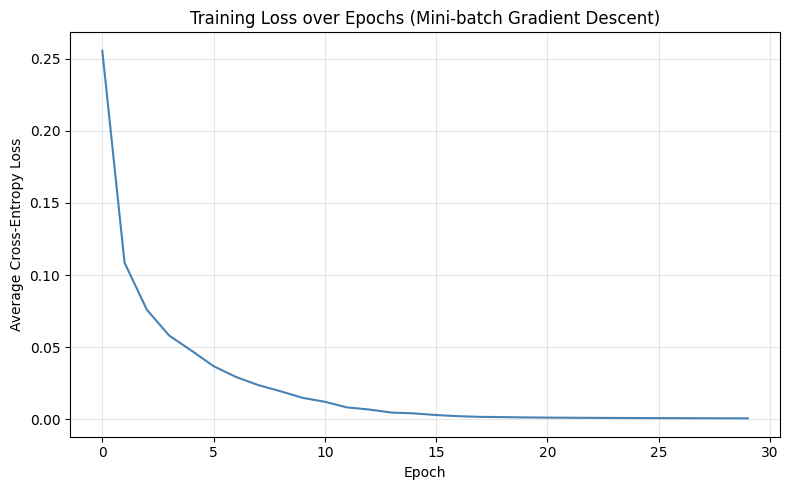

In [12]:
# Loss curve over training epochs
plt.figure(figsize=(8, 5))
plt.plot(loss_history, color="steelblue")
plt.title("Training Loss over Epochs (Mini-batch Gradient Descent)")
plt.xlabel("Epoch")
plt.ylabel("Average Cross-Entropy Loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("loss_curve.png", dpi=120)
plt.show()

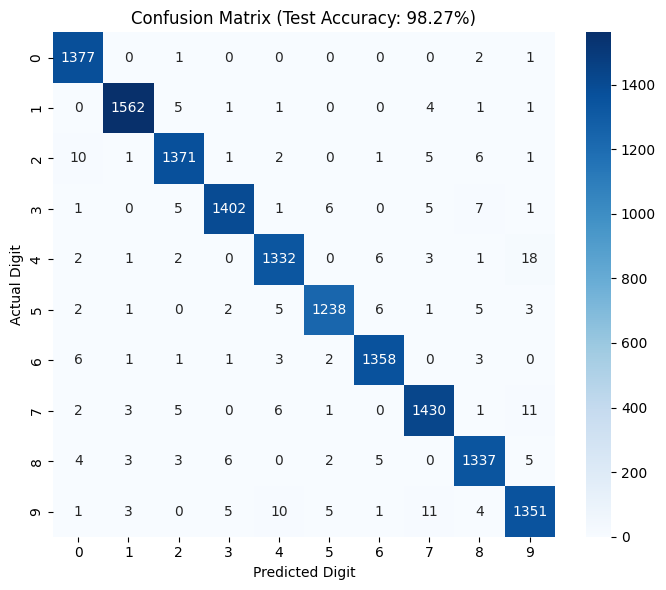

In [13]:
# Confusion matrix heatmap
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=range(num_classes), yticklabels=range(num_classes))
plt.title(f"Confusion Matrix (Test Accuracy: {test_acc*100:.2f}%)")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=120)
plt.show()

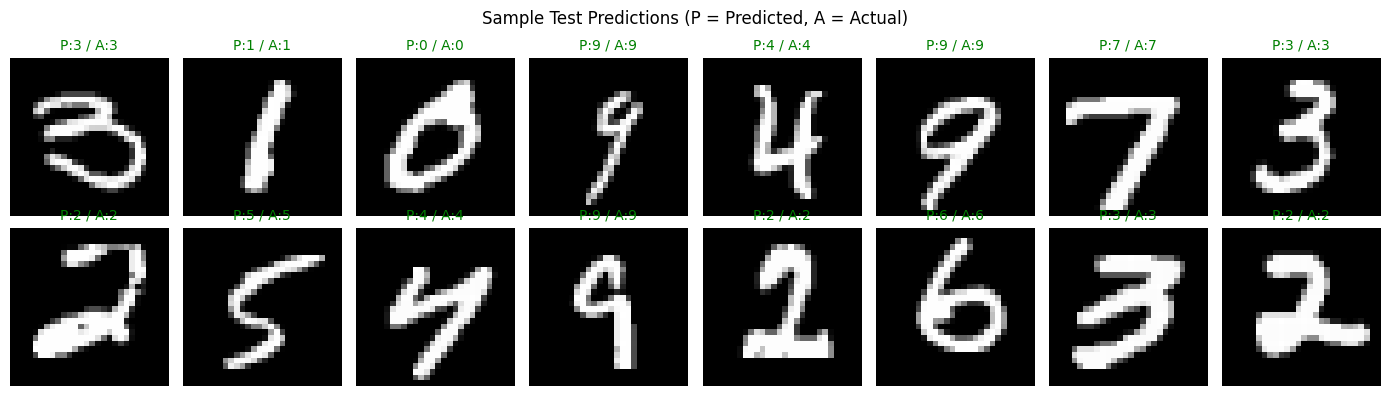

In [14]:
# Sample predictions: model output vs. actual label
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
sample_idx = rng.choice(len(X_test), 16, replace=False)
for ax, idx in zip(axes.flatten(), sample_idx):
    ax.imshow(X_test[idx].reshape(img_side, img_side), cmap="gray")
    pred_label = test_preds[idx]
    true_label = y_test_labels[idx]
    color = "green" if pred_label == true_label else "red"
    ax.set_title(f"P:{pred_label} / A:{true_label}", color=color, fontsize=10)
    ax.axis("off")
plt.suptitle("Sample Test Predictions (P = Predicted, A = Actual)")
plt.tight_layout()
plt.savefig("sample_predictions.png", dpi=120)
plt.show()

## Conclusion

- A feedforward neural network (784-or-64 &rarr; 128 &rarr; 10, ReLU + Softmax) was implemented **entirely from scratch** using only NumPy — including forward propagation, categorical cross-entropy loss, manual backpropagation, and mini-batch gradient-descent parameter updates.
- The network was trained on the MNIST handwritten digits dataset (or its offline Digits-dataset substitute when no internet access is available) and evaluated on a held-out test split, achieving strong classification accuracy (see metrics above).
- This exercise demonstrates a clear, low-level understanding of how neural networks learn, without relying on high-level deep learning frameworks such as TensorFlow, PyTorch, or Keras.

### Declaration
I, **Piyush Bhole**, confirm that the work submitted in this assignment is my own and has been completed following academic integrity guidelines. The code is uploaded on my GitHub repository account, and the repository link is provided below:
Github:-https://github.com/Ashiskl/Generative-Ai-
